# Genetic Algorithm for Engineering Signal Parameter Estimation

## Objective

Implement a real-coded genetic algorithm to estimate
the unknown parameters of a damped oscillatory signal
from noisy measurements.

The signal model is:
$$
y(t) = A e^{-\alpha t} sin(2 \pi ft)
$$
The unknown parameters are:

- A: Initial amplitude
- alpha: Damping coefficient
- f: Frequency

The algorithm will minimise the mean squared error
between the observed signal and the predicted signal.

## 1. Importing the libraries

We use NumPy for numerical computation and random-number
generation, Matplotlib for visualisation, and Pandas
for presenting the parameter-estimation results.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
rng = np.random.default_rng(42)

## 2. Signal model

Define the mathematical model of the damped oscillatory
signal.

The model depends on three parameters:

- A: Initial amplitude
- alpha: Damping coefficient
- f: Frequency

In [3]:
def damped_signal(t, A, alpha, f):

    signal = (
        A
        * np.exp(-alpha * t)
        * np.sin(2 * np.pi * f * t)
    )

    return signal

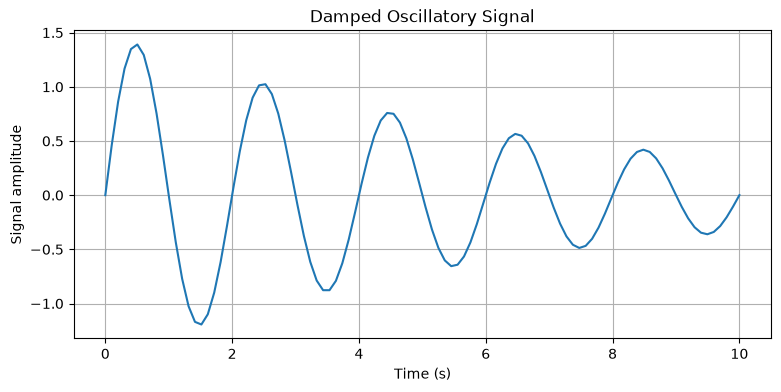

In [4]:
test_time = np.linspace(0, 10, 100)

test_signal = damped_signal(
    test_time,
    A=1.5,
    alpha=0.15,
    f=0.5
)

plt.figure(figsize=(9, 4))

plt.plot(test_time, test_signal)

plt.xlabel("Time (s)")
plt.ylabel("Signal amplitude")
plt.title("Damped Oscillatory Signal")

plt.grid(True)
plt.show()

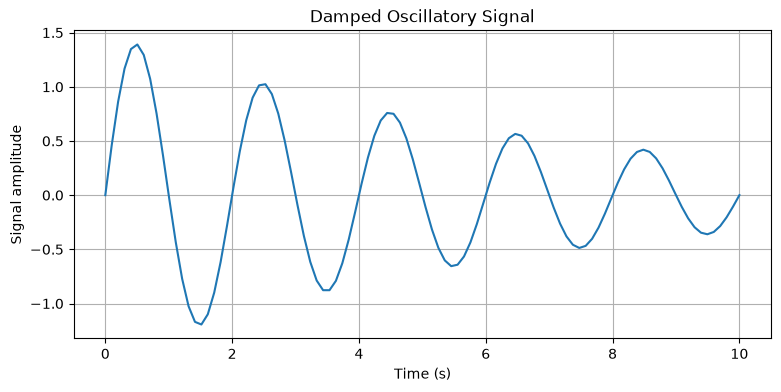

In [5]:
test_time = np.linspace(0, 10, 100)

test_signal = damped_signal(
    test_time,
    A=1.5,
    alpha=0.15,
    f=0.5
)

plt.figure(figsize=(9, 4))

plt.plot(test_time, test_signal)

plt.xlabel("Time (s)")
plt.ylabel("Signal amplitude")
plt.title("Damped Oscillatory Signal")

plt.grid(True)
plt.show()

## 3. Generating observed measurements

For this experiment, we simulate measurements from
a system with known parameters.

We define the true signal and introduce Gaussian
measurement noise.

The genetic algorithm will receive only the noisy
measurements, not the true parameters.

In [6]:
# True parameters used to generate the signal
true_parameters = np.array([1.5, 0.15, 0.5])

# Generate measurement time points
time = np.linspace(0, 20, 400)

# Measurement noise level
noise_std = 0.05

# Generate the ideal signal
true_signal = damped_signal(
    time,
    *true_parameters
)

# Add random measurement noise
observed_signal = (
    true_signal
    + rng.normal(
        loc=0.0,
        scale=noise_std,
        size=len(time)
    )
)

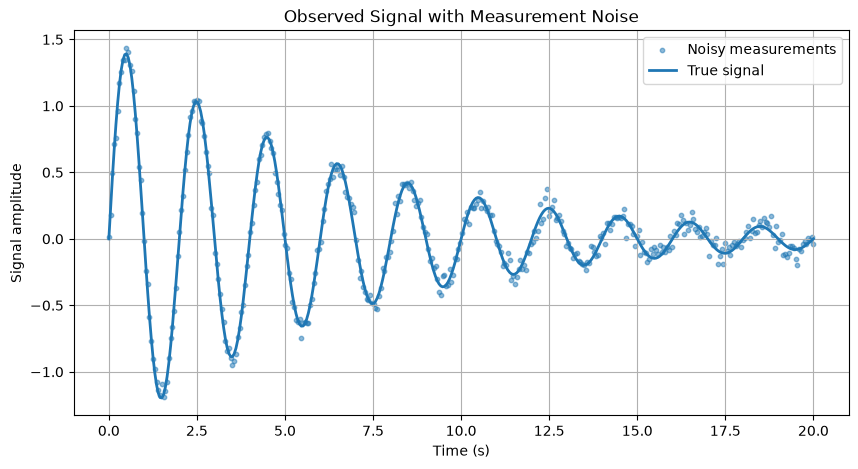

In [7]:
plt.figure(figsize=(10, 5))

plt.scatter(
    time,
    observed_signal,
    s=10,
    alpha=0.5,
    label="Noisy measurements"
)

plt.plot(
    time,
    true_signal,
    label="True signal",
    linewidth=2
)

plt.xlabel("Time (s)")
plt.ylabel("Signal amplitude")

plt.title("Observed Signal with Measurement Noise")

plt.legend()
plt.grid(True)

plt.show()

## 4. Objective-function definition

The objective function measures how closely a candidate
parameter combination reproduces the observed signal.

For each candidate $[A, \alpha, f]$, we:

1. Predict the signal using the mathematical model.
2. Calculate the difference between the predicted
   and observed measurements.
3. Square the differences.
4. Calculate their average.

This gives the mean squared error (MSE).

Our objective is to minimise the MSE.

In [8]:
def objective_function(
    candidate_parameters,
    time,
    observed_signal
):

    A, alpha, f = candidate_parameters

    predicted_signal = damped_signal(
        time,
        A,
        alpha,
        f
    )

    errors = observed_signal - predicted_signal

    mse = np.mean(errors ** 2)

    return mse

In [9]:
test_candidate = np.array([1.2, 0.20, 0.45])

test_mse = objective_function(
    test_candidate,
    time,
    observed_signal
)

print("Test candidate:", test_candidate)
print("Mean squared error:", test_mse)

Test candidate: [1.2  0.2  0.45]
Mean squared error: 0.13634775307243763


## 5. Search boundaries and algorithm parameters

Each individual contains three parameters.

We define lower and upper boundaries for each parameter
to restrict the algorithm's search space.

We also define the settings controlling the genetic
algorithm's evolutionary operations.

In [10]:
# Parameter boundaries
lower_bounds = np.array([
    0.5,    # Minimum amplitude
    0.01,   # Minimum damping coefficient
    0.20    # Minimum frequency
])

upper_bounds = np.array([
    2.5,    # Maximum amplitude
    0.50,   # Maximum damping coefficient
    0.80    # Maximum frequency
])


# Genetic algorithm settings
population_size = 40
number_generations = 100

# Selection settings
tournament_size = 3

# Crossover settings
crossover_probability = 0.9

# Mutation settings
mutation_probability = 0.15

mutation_scales = np.array([
    0.10,   # Amplitude mutation scale
    0.025,  # Damping mutation scale
    0.025   # Frequency mutation scale
])

# Elitism
elitism_count = 2

## 6. Population initialisation

Each individual is represented by three real-valued
parameters:
$$
[A, \alpha, f]
$$
The initial population is generated randomly within
the specified parameter boundaries.

In [11]:
population = rng.uniform(
    low=lower_bounds,
    high=upper_bounds,
    size=(population_size, 3)
)

print("Population shape:", population.shape)

print("\nFirst five individuals:")
print(population[:5])

Population shape: (40, 3)

First five individuals:
[[0.78604375 0.39061629 0.31892254]
 [2.32127645 0.33157183 0.22169763]
 [0.51085967 0.03531238 0.56355511]
 [2.10296362 0.12689088 0.70964531]
 [0.61446388 0.40247229 0.75667726]]


## 7. Population evaluation

Evaluate each individual using the objective function.

Candidates with smaller MSE values represent better
fits to the observed measurements.

In [12]:
objective_values = np.array([
    objective_function(
        individual,
        time,
        observed_signal
    )
    for individual in population
])

In [13]:
for i in range(5):

    print(
        f"Individual {i+1}: "
        f"Parameters = {population[i]}, "
        f"MSE = {objective_values[i]:.6f}"
    )

Individual 1: Parameters = [0.78604375 0.39061629 0.31892254], MSE = 0.187412
Individual 2: Parameters = [2.32127645 0.33157183 0.22169763], MSE = 0.356439
Individual 3: Parameters = [0.51085967 0.03531238 0.56355511], MSE = 0.217835
Individual 4: Parameters = [2.10296362 0.12689088 0.70964531], MSE = 0.596588
Individual 5: Parameters = [0.61446388 0.40247229 0.75667726], MSE = 0.190696


In [14]:
best_index = np.argmin(objective_values)

best_candidate = population[best_index]

best_mse = objective_values[best_index]

print("\nBest initial candidate:", best_candidate)
print("Best initial MSE:", best_mse)


Best initial candidate: [1.75202496 0.18672209 0.50764355]
Best initial MSE: 0.012221515570352337


## 8. Tournament selection

Randomly select a specified number of individuals
from the population.

The individual with the smallest objective value
wins the tournament and is selected as a parent.

In [15]:
def tournament_selection(
    population,
    objective_values,
    tournament_size
):

    competitor_indices = rng.choice(
        len(population),
        size=tournament_size,
        replace=False
    )

    winner_index = competitor_indices[
        np.argmin(
            objective_values[competitor_indices]
        )
    ]

    return population[winner_index].copy()

In [16]:
parent = tournament_selection(
    population,
    objective_values,
    tournament_size
)

print("Selected parent:", parent)

print(
    "Parent MSE:",
    objective_function(parent, time, observed_signal)
)

Selected parent: [1.35580643 0.3093839  0.58077747]
Parent MSE: 0.16243721754802418


## 9. Arithmetic crossover

Crossover combines the parameter values of two parents
to produce an offspring.

We use real-valued arithmetic crossover.

A separate random blending coefficient is generated
for each parameter.

In [17]:
def arithmetic_crossover(parent1, parent2):

    alpha = rng.random(size=parent1.shape)

    child = (
        alpha * parent1
        + (1 - alpha) * parent2
    )

    return child

In [18]:
parent1 = np.array([1.2, 0.20, 0.45])

parent2 = np.array([1.8, 0.10, 0.60])

child = arithmetic_crossover(parent1, parent2)

print("Parent 1:", parent1)
print("Parent 2:", parent2)
print("Offspring:", child)

Parent 1: [1.2  0.2  0.45]
Parent 2: [1.8 0.1 0.6]
Offspring: [1.29821743 0.1989133  0.51660459]


## 10. Gaussian mutation

Mutation introduces random changes into an offspring.

Each parameter has an independent probability of mutation.

The size of the change is controlled by the corresponding
mutation scale.

We also enforce the parameter boundaries after mutation.

In [19]:
def mutate(
    child,
    mutation_probability,
    mutation_scales
):

    mutated_child = child.copy()

    # Determine which parameters will mutate
    mutation_mask = (
        rng.random(size=mutated_child.shape)
        < mutation_probability
    )

    # Generate random changes
    mutation_values = rng.normal(
        loc=0.0,
        scale=mutation_scales,
        size=mutated_child.shape
    )

    # Apply changes only to selected parameters
    mutated_child += mutation_mask * mutation_values

    # Enforce parameter boundaries
    mutated_child = np.clip(
        mutated_child,
        lower_bounds,
        upper_bounds
    )

    return mutated_child

In [20]:
test_child = np.array([1.4, 0.18, 0.48])

mutated_child = mutate(
    test_child,
    mutation_probability,
    mutation_scales
)

print("Before mutation:", test_child)
print("After mutation:", mutated_child)

Before mutation: [1.4  0.18 0.48]
After mutation: [1.4        0.18       0.51637614]


## 11. Complete genetic algorithm

The algorithm performs the following operations:

1. Evaluate the population.
2. Identify the best candidates.
3. Record the population's performance.
4. Preserve elite candidates.
5. Select parents through tournament selection.
6. Apply crossover.
7. Apply mutation.
8. Construct the next generation.
9. Repeat until the maximum number of generations
   is reached.

In [21]:
# Store the results from each generation
history = {
    "best_mse": [],
    "mean_mse": [],
    "best_parameters": []
}


# Evolutionary process
for generation in range(number_generations + 1):

    # Evaluate the current population
    objective_values = np.array([
        objective_function(
            individual,
            time,
            observed_signal
        )
        for individual in population
    ])

    # Identify the best candidate
    best_index = np.argmin(objective_values)

    best_candidate = population[best_index].copy()

    best_value = objective_values[best_index]

    # Record population performance
    history["best_mse"].append(best_value)

    history["mean_mse"].append(
        np.mean(objective_values)
    )

    history["best_parameters"].append(
        best_candidate
    )

    # Stop after recording the final generation
    if generation == number_generations:
        break

    # Create the next generation
    next_population = []

    # Preserve the elite candidates
    elite_indices = np.argsort(objective_values)[
        :elitism_count
    ]

    for index in elite_indices:

        next_population.append(
            population[index].copy()
        )

    # Generate the remaining individuals
    while len(next_population) < population_size:

        # Select two parents
        parent1 = tournament_selection(
            population,
            objective_values,
            tournament_size
        )

        parent2 = tournament_selection(
            population,
            objective_values,
            tournament_size
        )

        # Apply crossover
        if rng.random() < crossover_probability:

            child = arithmetic_crossover(
                parent1,
                parent2
            )

        else:

            child = parent1.copy()

        # Apply mutation
        child = mutate(
            child,
            mutation_probability,
            mutation_scales
        )

        # Add offspring to the new population
        next_population.append(child)

    # Replace the current population
    population = np.array(next_population)

## 12. Parameter-estimation results

Identify the best parameter combination found across
all recorded generations.

Compare the estimated parameters with the known values
used to generate the simulated signal.

The true values are used only for evaluation after
the optimisation process.

In [22]:
best_generation_index = np.argmin(
    history["best_mse"]
)

estimated_parameters = np.array(
    history["best_parameters"][best_generation_index]
)

estimated_mse = history["best_mse"][
    best_generation_index
]

parameter_names = [
    "Amplitude (A)",
    "Damping coefficient (alpha)",
    "Frequency (f)"
]

results = pd.DataFrame({

    "Parameter": parameter_names,

    "True Value": true_parameters,

    "Estimated Value": estimated_parameters,

    "Absolute Error": np.abs(
        true_parameters - estimated_parameters
    )

})

print("Estimated parameters:")
display(results)

print("Best generation:", best_generation_index)

print("Estimated MSE:", estimated_mse)

Estimated parameters:


,Parameter,True Value,Estimated Value,Absolute Error
0,Amplitude (A),1.50,1.501457,0.001457
1,Damping coefficient (alpha),0.15,0.150993,0.000993
2,Frequency (f),0.50,0.500023,0.000023


Best generation: 100
Estimated MSE: 0.0022588208786396263


In [23]:
true_parameter_mse = objective_function(
    true_parameters,
    time,
    observed_signal
)

print("MSE using estimated parameters:", estimated_mse)

print("MSE using true parameters:", true_parameter_mse)

MSE using estimated parameters: 0.0022588208786396263
MSE using true parameters: 0.0022618003399644373


## 13. Convergence analysis

Examine the best and mean objective values across
successive generations.

This helps us understand how the population changes
and whether the algorithm is finding better solutions.

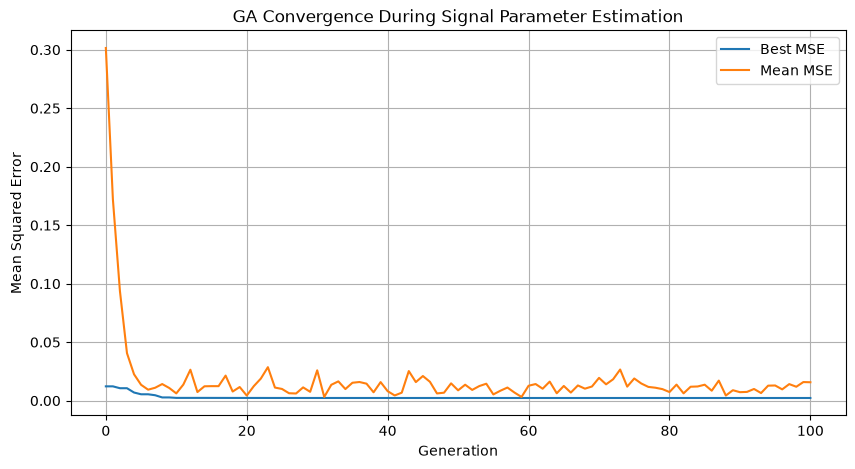

In [24]:
plt.figure(figsize=(10, 5))

plt.plot(
    history["best_mse"],
    label="Best MSE"
)

plt.plot(
    history["mean_mse"],
    label="Mean MSE"
)

plt.xlabel("Generation")

plt.ylabel("Mean Squared Error")

plt.title("GA Convergence During Signal Parameter Estimation")

plt.legend()

plt.grid(True)

plt.show()

## 14. Signal reconstruction

Use the estimated parameters to reconstruct the signal.

Compare the reconstructed signal with the noisy observations
and the ideal signal used to generate the measurements.

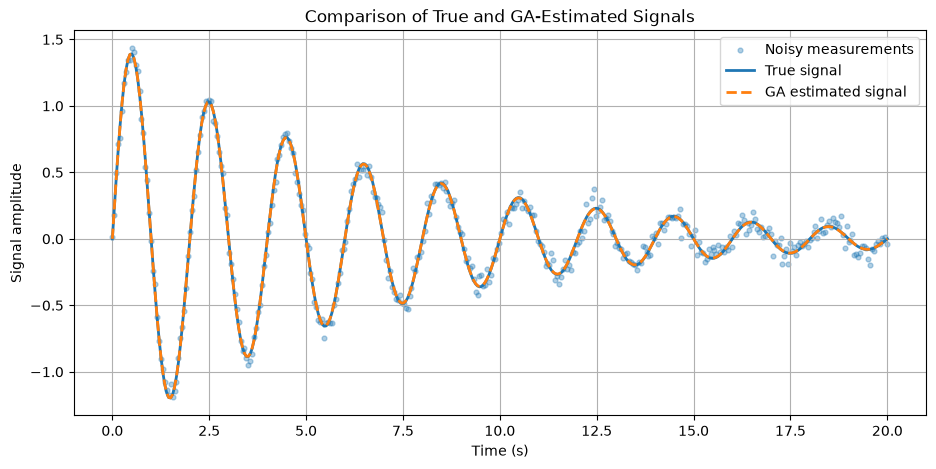

In [27]:
estimated_signal = damped_signal(
    time,
    *estimated_parameters
)

plt.figure(figsize=(11, 5))

plt.scatter(
    time,
    observed_signal,
    s=12,
    alpha=0.35,
    label="Noisy measurements"
)

plt.plot(
    time,
    true_signal,
    linewidth=2,
    label="True signal"
)

plt.plot(
    time,
    estimated_signal,
    linestyle="--",
    linewidth=2,
    label="GA estimated signal"
)

plt.xlabel("Time (s)")

plt.ylabel("Signal amplitude")

plt.title("Comparison of True and GA-Estimated Signals")

plt.legend()

plt.grid(True)

plt.show()

# Evaluating the Performance of the Genetic Algorithm

***Objective:*** *Go beyond obtaining an estimated solution and investigate how reliable, accurate and consistent the genetic algorithm is.*

There is an important distinction in computational research:

**Obtaining a result is not the same as demonstrating that the result is reliable.**

A working genetic algorithm might produce a good estimate in one run but a different estimate in another because its search process involves randomness.

We will investigate this systematically.

## 1. Parameter-estimation accuracy

Compare the estimated parameters with the true parameters.

Calculate the absolute and percentage errors for
amplitude, damping coefficient and frequency.

In [28]:
absolute_errors = np.abs(
    true_parameters - estimated_parameters
)

percentage_errors = (
    absolute_errors / np.abs(true_parameters)
) * 100

accuracy_table = pd.DataFrame({

    "Parameter": ["A", "alpha", "f"],

    "True Value": true_parameters,

    "Estimated Value": estimated_parameters,

    "Absolute Error": absolute_errors,

    "Percentage Error (%)": percentage_errors

})

display(accuracy_table)

,Parameter,True Value,Estimated Value,Absolute Error,Percentage Error (%)
0,A,1.50,1.501457,0.001457,0.097121
1,alpha,0.15,0.150993,0.000993,0.662084
2,f,0.50,0.500023,0.000023,0.004610


## 2. Signal-fitting performance

Calculate the mean squared error and root mean squared
error using the estimated parameters.

Compare these values with the errors obtained when
using the known true parameters.

In [29]:
# Reconstruct signal using estimated parameters
estimated_signal = damped_signal(
    time,
    *estimated_parameters
)

# Calculate residuals
residuals = observed_signal - estimated_signal

# Calculate MSE and RMSE
estimated_mse = np.mean(residuals ** 2)

estimated_rmse = np.sqrt(estimated_mse)


# Evaluate the model using true parameters
true_parameter_mse = objective_function(
    true_parameters,
    time,
    observed_signal
)

true_parameter_rmse = np.sqrt(
    true_parameter_mse
)

print("Estimated parameter model")
print("MSE:", estimated_mse)
print("RMSE:", estimated_rmse)

print("\nTrue parameter model")
print("MSE:", true_parameter_mse)
print("RMSE:", true_parameter_rmse)

Estimated parameter model
MSE: 0.0022588208786396263
RMSE: 0.04752705417590729

True parameter model
MSE: 0.0022618003399644373
RMSE: 0.047558388744410145


## 3. Residual analysis

Calculate the residuals between the observed signal
and the signal reconstructed using the estimated parameters.

Visualise the residuals against time and examine their
mean and standard deviation.

In [31]:
residual_mean = np.mean(residuals)

residual_std = np.std(residuals, ddof=1)

residual_rmse = np.sqrt(
    np.mean(residuals ** 2)
)

print("Residual mean:", residual_mean)

print("Residual standard deviation:", residual_std)

print("Residual RMSE:", residual_rmse)

Residual mean: -0.00030283148561330146
Residual standard deviation: 0.04758560861330549
Residual RMSE: 0.04752705417590729


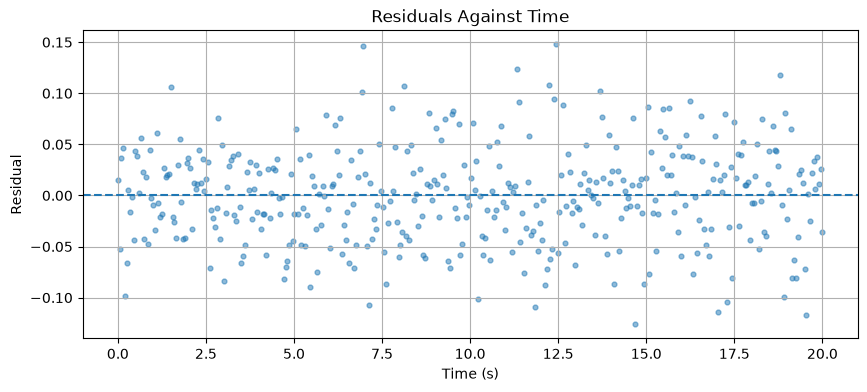

In [32]:
plt.figure(figsize=(10, 4))

plt.scatter(
    time,
    residuals,
    s=12,
    alpha=0.5
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Time (s)")

plt.ylabel("Residual")

plt.title("Residuals Against Time")

plt.grid(True)

plt.show()

In [38]:
def tournament_selection(
    population,
    objective_values,
    tournament_size,
    rng
):

    competitor_indices = rng.choice(
        len(population),
        size=tournament_size,
        replace=False
    )

    winner_index = competitor_indices[
        np.argmin(
            objective_values[competitor_indices]
        )
    ]

    return population[winner_index].copy()

In [39]:
def arithmetic_crossover(parent1, parent2, rng):

    alpha = rng.random(size=parent1.shape)

    child = (
        alpha * parent1
        + (1 - alpha) * parent2
    )

    return child

In [40]:
def mutate(
    child,
    mutation_probability,
    mutation_scales,
    lower_bounds,
    upper_bounds,
    rng
):

    mutated_child = child.copy()

    mutation_mask = (
        rng.random(size=mutated_child.shape)
        < mutation_probability
    )

    mutation_values = rng.normal(
        loc=0.0,
        scale=mutation_scales,
        size=mutated_child.shape
    )

    mutated_child += mutation_mask * mutation_values

    mutated_child = np.clip(
        mutated_child,
        lower_bounds,
        upper_bounds
    )

    return mutated_child

## 4. Repeated GA experiments

Create a function that runs the genetic algorithm
using a supplied random seed.

Keep the observed measurements and GA settings unchanged.

Only the random sequence used by the GA will change.

In [41]:
def run_genetic_algorithm(seed):

    # Create a separate random-number generator
    rng = np.random.default_rng(seed)

    # Generate a new initial population
    population = rng.uniform(
        low=lower_bounds,
        high=upper_bounds,
        size=(population_size, 3)
    )

    # Store results from each generation
    history = {
        "best_mse": [],
        "mean_mse": [],
        "best_parameters": []
    }

    # Evolutionary process
    for generation in range(number_generations + 1):

        # Evaluate population
        objective_values = np.array([
            objective_function(
                individual,
                time,
                observed_signal
            )
            for individual in population
        ])

        # Identify best candidate
        best_index = np.argmin(objective_values)

        best_candidate = population[best_index].copy()

        best_value = objective_values[best_index]

        # Record results
        history["best_mse"].append(best_value)

        history["mean_mse"].append(
            np.mean(objective_values)
        )

        history["best_parameters"].append(
            best_candidate.copy()
        )

        # Stop after recording final generation
        if generation == number_generations:
            break

        # Create next generation
        next_population = []

        # Preserve elite candidates
        elite_indices = np.argsort(objective_values)[
            :elitism_count
        ]

        for index in elite_indices:

            next_population.append(
                population[index].copy()
            )

        # Generate remaining individuals
        while len(next_population) < population_size:

            # Select parents
            parent1 = tournament_selection(
                population,
                objective_values,
                tournament_size,
                rng
            )

            parent2 = tournament_selection(
                population,
                objective_values,
                tournament_size,
                rng
            )

            # Apply crossover
            if rng.random() < crossover_probability:

                child = arithmetic_crossover(
                    parent1,
                    parent2,
                    rng
                )

            else:

                child = parent1.copy()

            # Apply mutation
            child = mutate(
                child,
                mutation_probability,
                mutation_scales,
                lower_bounds,
                upper_bounds,
                rng
            )

            next_population.append(child)

        # Replace population
        population = np.array(next_population)

    return history

## 5. Repeatability experiment

Run the genetic algorithm five times using different
random seeds.

The observed measurements and algorithm settings
remain unchanged.

Record the estimated parameters and fitting error
from each run.

In [45]:
seeds = [11, 23, 37, 52, 68]

run_histories = {}

results = []

for seed in seeds:

    # Run the genetic algorithm
    history = run_genetic_algorithm(seed)

    run_histories[seed] = history

    # Identify the best candidate across generations
    best_index = np.argmin(history["best_mse"])

    estimated_parameters_run = np.array(
        history["best_parameters"][best_index]
    )

    estimated_mse_run = history["best_mse"][best_index]

    estimated_rmse_run = np.sqrt(estimated_mse_run)

    # Calculate parameter errors for evaluation
    absolute_errors_run = np.abs(
        true_parameters - estimated_parameters_run
    )

    # Store results
    results.append({

        "Seed": seed,

        "A estimate": estimated_parameters_run[0],

        "Alpha estimate": estimated_parameters_run[1],

        "Frequency estimate": estimated_parameters_run[2],

        "MSE": estimated_mse_run,

        "RMSE": estimated_rmse_run,

        "A error": absolute_errors_run[0],

        "Alpha error": absolute_errors_run[1],

        "Frequency error": absolute_errors_run[2]

    })


repeatability_table = pd.DataFrame(results)

display(repeatability_table)

,Seed,A estimate,Alpha estimate,Frequency estimate,MSE,RMSE,A error,Alpha error,Frequency error
0,11,1.499911,0.150882,0.500023,0.002259,0.047525,0.000089,0.000882,0.000023
1,23,1.499295,0.150817,0.500022,0.002259,0.047525,0.000705,0.000817,0.000022
2,37,1.499352,0.150823,0.500022,0.002259,0.047525,0.000648,0.000823,0.000022
3,52,1.499958,0.150912,0.500027,0.002259,0.047525,0.000042,0.000912,0.000027
4,68,1.502639,0.151196,0.500020,0.002259,0.047530,0.002639,0.001196,0.000020


## 6. Convergence comparison

Plot the best MSE obtained in each generation
for all five independent runs.

This allows us to compare how quickly and consistently
the algorithm finds good candidate solutions.

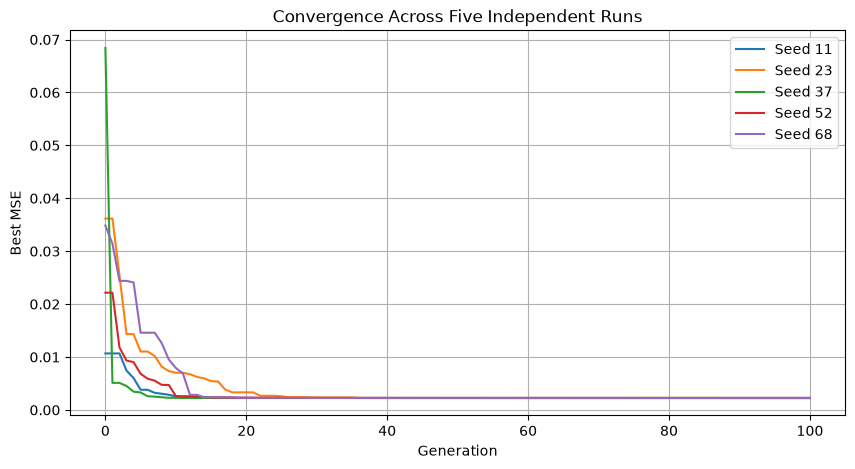

In [46]:
plt.figure(figsize=(10, 5))

for seed, history in run_histories.items():

    plt.plot(
        history["best_mse"],
        label=f"Seed {seed}"
    )

plt.xlabel("Generation")

plt.ylabel("Best MSE")

plt.title("Convergence Across Five Independent Runs")

plt.legend()

plt.grid(True)

plt.show()

## 7. Summary statistics across independent runs

Calculate the mean and standard deviation of the
estimated parameters and MSE values.

The mean summarises the average result, while the
standard deviation indicates how much the results vary.

In [47]:
summary_statistics = repeatability_table[
    [
        "A estimate",
        "Alpha estimate",
        "Frequency estimate",
        "MSE",
        "RMSE"
    ]
].agg(["mean", "std"])

display(summary_statistics)

,A estimate,Alpha estimate,Frequency estimate,MSE,RMSE
mean,1.500231,0.150926,0.500023,2.258718e-03,0.047526
std,0.001381,0.000156,0.000002,1.994762e-07,0.000002


In [48]:
best_run_index = repeatability_table["MSE"].idxmin()

best_run = repeatability_table.loc[best_run_index]

best_run_parameters = np.array([
    best_run["A estimate"],
    best_run["Alpha estimate"],
    best_run["Frequency estimate"]
])

print("Best random seed:", int(best_run["Seed"]))

print("\nBest estimated parameters:")
print(best_run_parameters)

print("\nBest MSE:", best_run["MSE"])

Best random seed: 23

Best estimated parameters:
[1.49929476 0.15081679 0.50002227]

Best MSE: 0.0022586185771634147


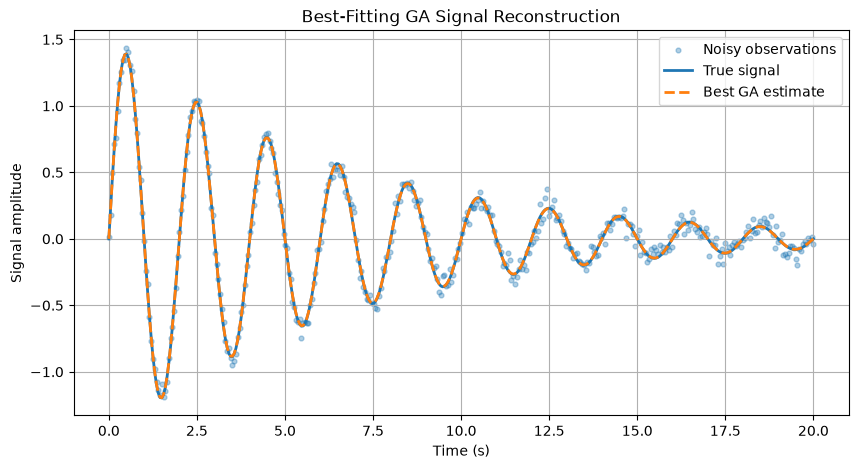

In [49]:
best_estimated_signal = damped_signal(
    time,
    *best_run_parameters
)

plt.figure(figsize=(10, 5))

plt.scatter(
    time,
    observed_signal,
    s=12,
    alpha=0.35,
    label="Noisy observations"
)

plt.plot(
    time,
    true_signal,
    linewidth=2,
    label="True signal"
)

plt.plot(
    time,
    best_estimated_signal,
    linestyle="--",
    linewidth=2,
    label="Best GA estimate"
)

plt.xlabel("Time (s)")

plt.ylabel("Signal amplitude")

plt.title("Best-Fitting GA Signal Reconstruction")

plt.legend()

plt.grid(True)

plt.show()